# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent, HumanRuleAgent, EpsilonGreedyAgent, UCBAgent

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [4]:
TEAM_LOG_FILES = [
    "fishing_log_antonsen.json",
    "fishing_log_raad.json",
    "fishing_log_toukouro.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
# spots, catches = choices(logs[0], season=1)

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [5]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

All results: regret is in kg; efficiency is in percent.
 season                agent    n  regret_mean  regret_sd  regret_median  regret_p10  regret_p90  efficiency_mean  efficiency_sd  catch_mean
      1 Epsilon-greedy (0.1) 1000        55.14      48.35          42.40        6.39      128.42            78.86          18.00      204.70
      1           Human rule 1000        78.86      32.14          75.35       39.90      123.09            69.82          11.20      182.53
      1               Random 1000        79.32      29.86          77.50       42.18      119.41            69.67          10.19      180.89
      1            UCB (c=2) 1000        25.06      11.17          22.55       13.99       39.61            90.25           4.46      235.27
      2 Epsilon-greedy (0.1) 1000        24.16      19.83          20.30        1.00       53.24            72.41          21.98       63.19
      2           Human rule 1000        26.38      13.81          25.85        9.20       45.20  

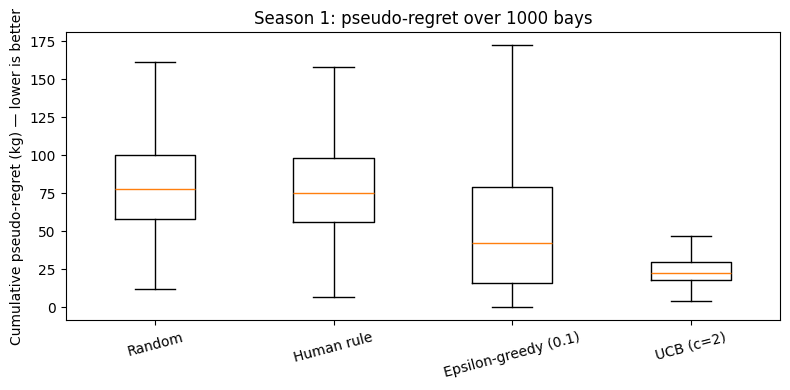

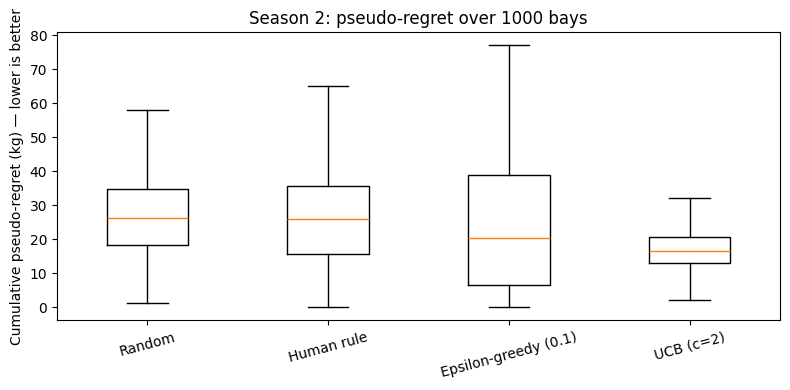

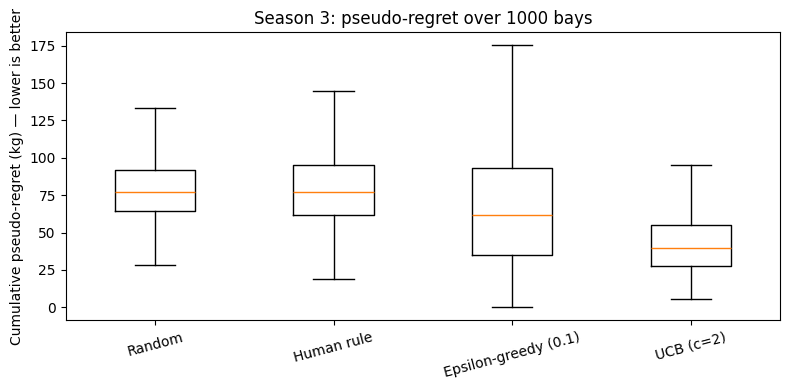

In [8]:
# Task 5, Part 1: evaluate all four agents on the SAME 1,000 bays per season.
# Each agent gets its own reproducible random generator; the simulator is not
# revealed to the agents. Hidden means are used ONLY after play() for evaluation.
import pandas as pd

N_BAYS = 1000
AGENT_FACTORIES = {
    "Random": lambda seed: RandomAgent(seed=seed),
    "Human rule": lambda seed: HumanRuleAgent(n_spots=5, seed=seed),
    "Epsilon-greedy (0.1)": lambda seed: EpsilonGreedyAgent(seed=seed, epsilon=0.1),
    "UCB (c=2)": lambda seed: UCBAgent(seed=seed, c=2.0),
}

def evaluate_finished_bay(bay):
    """Compute pseudo-regret and efficiency after the agent has finished."""
    info = bay.reveal()  # Never used by the agent itself!
    expected = 0.0
    for day, (spot, catch) in enumerate(bay.history, start=1):
        means = info["means"]
        if "means_after_change" in info and day >= info["change_day"]:
            means = info["means_after_change"]
        expected += means[spot]
    optimal = bay.best_possible()
    return {
        "actual": bay.total,
        "expected": expected,
        "optimal": optimal,
        "regret": optimal - expected,
        "efficiency": 100 * expected / optimal,
        "luck": bay.total - expected,
    }

records = []
for season in (1, 2, 3):
    for bay_seed in range(N_BAYS):
        for name, make_agent in AGENT_FACTORIES.items():
            bay = FishingBay(season=season, seed=bay_seed)
            agent = make_agent(seed=1_000_000 + bay_seed)
            play(agent, bay)
            records.append({
                "season": season,
                "bay_seed": bay_seed,
                "agent": name,
                **evaluate_finished_bay(bay),
            })

results = pd.DataFrame(records)
summary = (results.groupby(["season", "agent"])
           .agg(n=("regret", "size"),
                regret_mean=("regret", "mean"),
                regret_sd=("regret", "std"),
                regret_median=("regret", "median"),
                regret_p10=("regret", lambda x: x.quantile(.10)),
                regret_p90=("regret", lambda x: x.quantile(.90)),
                efficiency_mean=("efficiency", "mean"),
                efficiency_sd=("efficiency", "std"),
                catch_mean=("actual", "mean"))
           .reset_index())
print("All results: regret is in kg; efficiency is in percent.")
print(summary.round(2).to_string(index=False))

# Show distributions, not only averages (one panel per season).
for season in (1, 2, 3):
    fig, ax = plt.subplots(figsize=(8, 4))
    labels = list(AGENT_FACTORIES)
    data = [results.loc[(results.season == season) &
                        (results.agent == name), "regret"].to_numpy()
            for name in labels]
    ax.boxplot(data, tick_labels=labels, showfliers=False)
    ax.set_title(f"Season {season}: pseudo-regret over {N_BAYS} bays")
    ax.set_ylabel("Cumulative pseudo-regret (kg) — lower is better")
    ax.tick_params(axis="x", labelrotation=15)
    fig.tight_layout()
    plt.show()

results.to_csv("task5_random_bays.csv", index=False)
summary.to_csv("task5_summary.csv", index=False)


## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [9]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)


# Task 5, Part 2: Compare agents with human players
PLAYER_NAMES = ["Kaisa", "Synne", "Fayad"]

comparison = []

for player, log in zip(PLAYER_NAMES, logs):
    for season in (1, 2, 3):

        # Reconstruct the original bay
        bay = FishingBay.from_log(log, season)

        # Replay the human player's choices
        spots, catches = choices(log, season)

        for spot in spots:
            bay.fish(spot)

        # Verify that the original catches match
        assert np.allclose(
            [catch for spot, catch in bay.history],
            catches
        )

        # Evaluate the human player
        comparison.append({
            "player": player,
            "season": season,
            "agent": "Human",
            **evaluate_finished_bay(bay),
        })

        # Evaluate all four agents on the same bay
        for name, make_agent in AGENT_FACTORIES.items():
            bay = FishingBay.from_log(log, season)
            agent = make_agent(seed=1_000_000 + season)

            play(agent, bay)

            comparison.append({
                "player": player,
                "season": season,
                "agent": name,
                **evaluate_finished_bay(bay),
            })

# Create results table
human_bay_results = pd.DataFrame(comparison)

regret_table = human_bay_results.pivot(
    index=["player", "season"],
    columns="agent",
    values="regret"
)

print("Cumulative pseudo-regret (kg): lower is better")
display(regret_table.round(1))

# Save results for the report
human_bay_results.to_csv(
    "task5_human_bays.csv", index=False
)


Cumulative pseudo-regret (kg): lower is better


agent          Epsilon-greedy (0.1)  Human  Human rule  Random  UCB (c=2)
player season                                                            
Fayad  1                        6.4   50.6        50.7    45.1       22.5
       2                       58.0   25.9        51.4    36.9       31.7
       3                       26.3   40.4        53.0    52.7       25.6
Kaisa  1                       50.4   69.8        52.8    74.0       22.6
       2                       40.3   29.3        50.4    44.2       22.3
       3                       95.6   64.5        59.7    46.2       36.2
Synne  1                       90.0  110.0       102.5   107.3       18.5
       2                       78.0   23.3        50.7    50.0       16.7
       3                       48.0   74.4       104.5    97.4       49.6

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [ ]:
# Your code here

## 4. One parameter

Study the effect of one parameter of one method.

In [ ]:
# Your code here

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [ ]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

# Your code here